# Experiment 12

AIM: Simulate Hit or Miss Transformation on images.

Enrollment No: 92400133081

### (Optional) Create the input image
The input image `hitmiss_input.png` is a binary image of thin lines. Run this cell only if the image file is not available.

In [1]:
import cv2
import numpy as np

img = np.zeros((300, 300), np.uint8)

# thin horizontal and vertical lines (3 x 3 = 9 crossings)
for p in (60, 150, 240):
    cv2.line(img, (20, p), (280, p), 255, 1)
    cv2.line(img, (p, 20), (p, 280), 255, 1)

# a circle and a diagonal line (shapes which do not match the pattern)
cv2.circle(img, (105, 105), 22, 255, 1)
cv2.line(img, (190, 190), (230, 230), 255, 1)

cv2.imwrite('hitmiss_input.png', img)

True

### Program

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the binary image
image = cv2.imread('hitmiss_input.png', 0)     # Replace with your image path

In [3]:
# Define the structuring element for the pattern to be detected (0 for don't care, 1 for foreground, -1 for background)
pattern = np.array([[-1, 1, -1],
                    [1, 1, 1],
                    [-1, 1, -1]], dtype=np.int8)

# Apply the Hit or Miss Transformation
result = cv2.morphologyEx(image, cv2.MORPH_HITMISS, pattern)

Number of hits : 9
Positions (row, column):
[[ 60  60]
 [ 60 150]
 [ 60 240]
 [150  60]
 [150 150]
 [150 240]
 [240  60]
 [240 150]
 [240 240]]


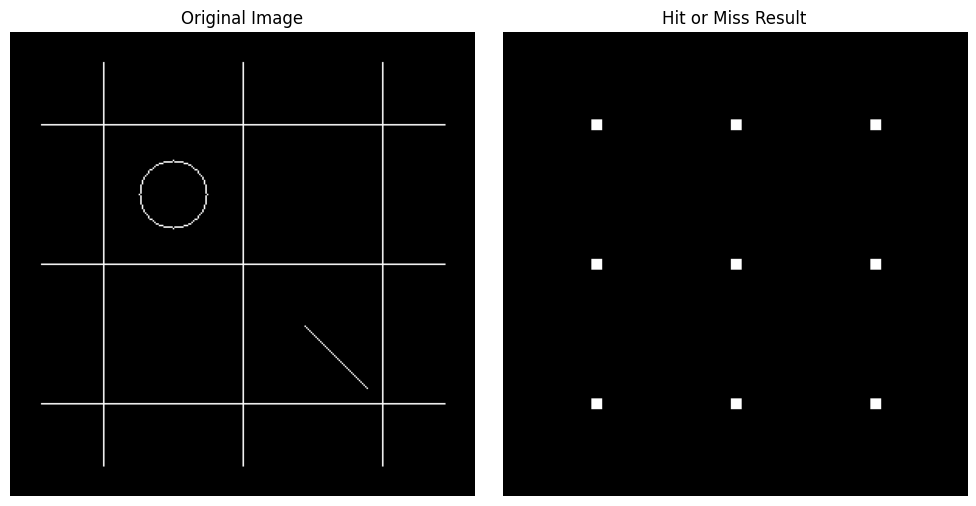

In [4]:
# Positions of the pixels where the pattern is found
hits = np.argwhere(result > 0)
print("Number of hits :", len(hits))
print("Positions (row, column):")
print(hits)

# Enlarge the single pixel hits so that they are visible in the display
result_display = cv2.dilate(result, np.ones((7, 7), np.uint8))

# Display the original image and the result
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(result_display, cmap='gray')
plt.title('Hit or Miss Result')
plt.axis('off')

plt.tight_layout()
plt.show()